In [2]:
!pip install seaborn

Defaulting to user installation because normal site-packages is not writeable
  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
!pip install lightgbm

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ------- -------------------------------- 0.3/1.4 MB ? eta -:--:--
   ------- -------------------------------- 0.3/1.4 MB ? eta -:--:--
   ------- --------------

In [3]:
!pip install xgboost

Defaulting to user installation because normal site-packages is not writeable
  Using cached xgboost-3.4.1-py3-none-win_amd64.whl.metadata (2.0 kB)
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.3/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.3/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.3/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.3/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.3/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.3/48.9 MB ? eta -:--:--
   ---------

In [20]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier
from sklearn.base import clone
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

In [19]:
import pandas as pd

url = (
    "https://archive.ics.uci.edu/ml/"
    "machine-learning-databases/wine-quality/winequality-red.csv"
)

df = pd.read_csv(url, sep=";")

print("Dataset Shape:", df.shape)
display(df.head())

Dataset Shape: (1599, 12)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [21]:
df.shape

(1599, 12)

In [22]:
print("\nFirst five rows:")
df.head()


First five rows:


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [23]:
df.tail()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
1594,6.2,0.600,0.08,2.0,0.090,32.0,44.0,0.99490,3.45,0.58,10.5,5
1595,5.9,0.550,0.10,2.2,0.062,39.0,51.0,0.99512,3.52,0.76,11.2,6
1596,6.3,0.510,0.13,2.3,0.076,29.0,40.0,0.99574,3.42,0.75,11.0,6
1597,5.9,0.645,0.12,2.0,0.075,32.0,44.0,0.99547,3.57,0.71,10.2,5
1598,6.0,0.310,0.47,3.6,0.067,18.0,42.0,0.99549,3.39,0.66,11.0,6


In [24]:
display(df.describe())

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000
mean,8.319637,0.527821,0.270976,2.538806,0.087467,15.874922,46.467792,0.996747,3.311113,0.658149,10.422983,5.636023
std,1.741096,0.179060,0.194801,1.409928,0.047065,10.460157,32.895324,0.001887,0.154386,0.169507,1.065668,0.807569
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000
25%,7.100000,0.390000,0.090000,1.900000,0.070000,7.000000,22.000000,0.995600,3.210000,0.550000,9.500000,5.000000
50%,7.900000,0.520000,0.260000,2.200000,0.079000,14.000000,38.000000,0.996750,3.310000,0.620000,10.200000,6.000000
75%,9.200000,0.640000,0.420000,2.600000,0.090000,21.000000,62.000000,0.997835,3.400000,0.730000,11.100000,6.000000
max,15.900000,1.580000,1.000000,15.500000,0.611000,72.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000


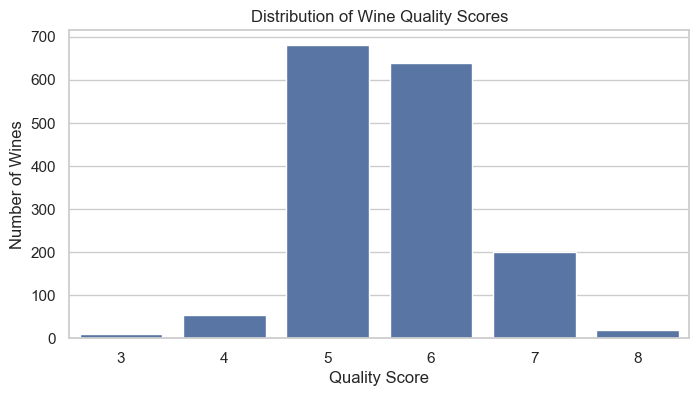

In [25]:
plt.figure(figsize=(8, 4))
sns.countplot(data=df, x="quality")
plt.title("Distribution of Wine Quality Scores")
plt.xlabel("Quality Score")
plt.ylabel("Number of Wines")
plt.show()

In [26]:
df["good_quality"] = (df["quality"] >= 7).astype(int)

print("\nClass distribution:")
print(df["good_quality"].value_counts())

print("\nClass distribution in percentages:")
print((df["good_quality"].value_counts(normalize=True) * 100).round(2))


Class distribution:
good_quality
0    1382
1     217
Name: count, dtype: int64

Class distribution in percentages:
good_quality
0    86.43
1    13.57
Name: proportion, dtype: float64


In [27]:
X = df.drop(columns=["quality", "good_quality"])
y = df["good_quality"]

X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full,
    test_size=0.20,
    random_state=42,
    stratify=y_train_full
)

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Test samples:", len(X_test))

Training samples: 1023
Validation samples: 256
Test samples: 320


In [28]:
bagging_model = BaggingClassifier(
    estimator=DecisionTreeClassifier(
        max_depth=5,
        random_state=42
    ),
    n_estimators=100,
    max_samples=1.0,
    bootstrap=True,
    random_state=42,
    n_jobs=-1
)

bagging_model.fit(X_train, y_train)

print("Bagging model trained successfully!")
print("Number of estimators:", len(bagging_model.estimators_))

Bagging model trained successfully!
Number of estimators: 100


In [29]:
bag_train_pred = bagging_model.predict(X_train)
bag_val_pred = bagging_model.predict(X_val)

print("Bagging Training Accuracy:",
      round(accuracy_score(y_train, bag_train_pred), 4))

print("Bagging Validation Accuracy:",
      round(accuracy_score(y_val, bag_val_pred), 4))

print("\nValidation Classification Report:")
print(classification_report(
    y_val,
    bag_val_pred,
    target_names=["Lower quality", "Good quality"],
    zero_division=0
))

Bagging Training Accuracy: 0.9423
Bagging Validation Accuracy: 0.8555

Validation Classification Report:
               precision    recall  f1-score   support

Lower quality       0.89      0.95      0.92       221
 Good quality       0.44      0.23      0.30        35

     accuracy                           0.86       256
    macro avg       0.67      0.59      0.61       256
 weighted avg       0.83      0.86      0.83       256



In [30]:
xgb_model = XGBClassifier(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=4,
    min_child_weight=3,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_alpha=0.0,
    reg_lambda=1.0,
    eval_metric="logloss",
    early_stopping_rounds=30,
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(
    X_train,
    y_train,
    eval_set=[(X_val, y_val)],
    verbose=False
)

print("XGBoost model trained successfully!")
print("Best iteration:", xgb_model.best_iteration)

XGBoost model trained successfully!
Best iteration: 114


In [31]:
xgb_train_pred = xgb_model.predict(X_train)
xgb_val_pred = xgb_model.predict(X_val)

print("XGBoost Training Accuracy:",
      round(accuracy_score(y_train, xgb_train_pred), 4))

print("XGBoost Validation Accuracy:",
      round(accuracy_score(y_val, xgb_val_pred), 4))

print("\nValidation Classification Report:")
print(classification_report(
    y_val,
    xgb_val_pred,
    target_names=["Lower quality", "Good quality"],
    zero_division=0
))

XGBoost Training Accuracy: 0.9443
XGBoost Validation Accuracy: 0.8672

Validation Classification Report:
               precision    recall  f1-score   support

Lower quality       0.89      0.96      0.93       221
 Good quality       0.53      0.26      0.35        35

     accuracy                           0.87       256
    macro avg       0.71      0.61      0.64       256
 weighted avg       0.84      0.87      0.85       256



In [32]:
lgbm_model = LGBMClassifier(
    n_estimators=500,
    learning_rate=0.05,
    num_leaves=15,
    max_depth=5,
    min_child_samples=20,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_alpha=0.0,
    reg_lambda=1.0,
    random_state=42,
    verbosity=-1,
    n_jobs=-1
)

lgbm_model.fit(
    X_train,
    y_train,
    eval_set=[(X_val, y_val)],
    eval_metric="binary_logloss",
    callbacks=[
        __import__("lightgbm").early_stopping(
            stopping_rounds=30,
            verbose=False
        )
    ]
)

print("LightGBM model trained successfully!")
print("Best iteration:", lgbm_model.best_iteration_)

C:\Users\hp\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


LightGBM model trained successfully!
Best iteration: 94


In [33]:
lgbm_train_pred = lgbm_model.predict(X_train)
lgbm_val_pred = lgbm_model.predict(X_val)

print("LightGBM Training Accuracy:",
      round(accuracy_score(y_train, lgbm_train_pred), 4))

print("LightGBM Validation Accuracy:",
      round(accuracy_score(y_val, lgbm_val_pred), 4))

print("\nValidation Classification Report:")
print(classification_report(
    y_val,
    lgbm_val_pred,
    target_names=["Lower quality", "Good quality"],
    zero_division=0
))

LightGBM Training Accuracy: 0.9668
LightGBM Validation Accuracy: 0.8672

Validation Classification Report:
               precision    recall  f1-score   support

Lower quality       0.89      0.96      0.93       221
 Good quality       0.53      0.29      0.37        35

     accuracy                           0.87       256
    macro avg       0.71      0.62      0.65       256
 weighted avg       0.84      0.87      0.85       256



In [34]:
models = {
    "Bagging": bagging_model,
    "XGBoost": xgb_model,
    "LightGBM": lgbm_model
}

comparison = []

for name, model in models.items():
    train_pred = model.predict(X_train)
    val_pred = model.predict(X_val)

    comparison.append({
        "Model": name,
        "Train Accuracy": accuracy_score(y_train, train_pred),
        "Validation Accuracy": accuracy_score(y_val, val_pred),
        "Precision": precision_score(y_val, val_pred, zero_division=0),
        "Recall": recall_score(y_val, val_pred, zero_division=0),
        "F1 Score": f1_score(y_val, val_pred, zero_division=0),
        "Train-Val Gap": (
            accuracy_score(y_train, train_pred)
            - accuracy_score(y_val, val_pred)
        )
    })

comparison_df = pd.DataFrame(comparison).set_index("Model")
display(comparison_df.round(4))

,Train Accuracy,Validation Accuracy,Precision,Recall,F1 Score,Train-Val Gap
Model,,,,,,
Bagging,0.9423,0.8555,0.4444,0.2286,0.3019,0.0869
XGBoost,0.9443,0.8672,0.5294,0.2571,0.3462,0.0771
LightGBM,0.9668,0.8672,0.5263,0.2857,0.3704,0.0996


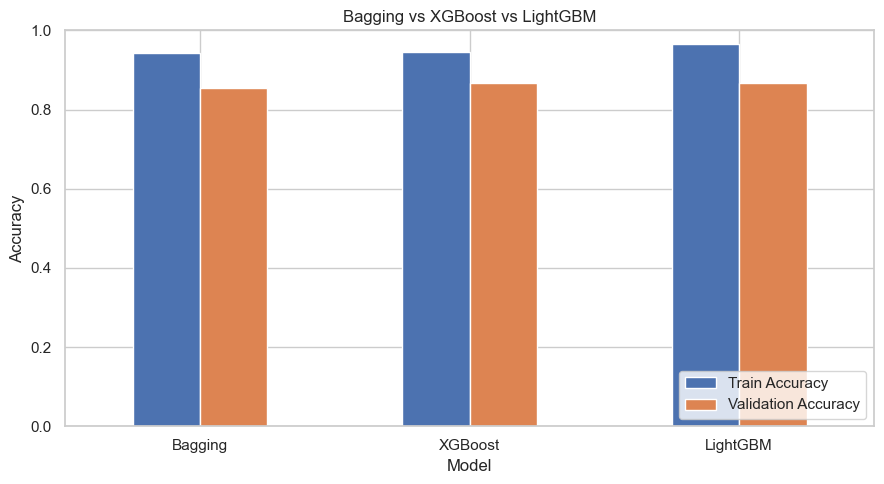

In [35]:
comparison_df[
    ["Train Accuracy", "Validation Accuracy"]
].plot(kind="bar", figsize=(9, 5))

plt.title("Bagging vs XGBoost vs LightGBM")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [36]:
regularization_configs = {
    "Baseline": {
        "reg_alpha": 0.0,
        "reg_lambda": 0.0
    },
    "L1 only": {
        "reg_alpha": 1.0,
        "reg_lambda": 0.0
    },
    "L2 only": {
        "reg_alpha": 0.0,
        "reg_lambda": 5.0
    },
    "L1 + L2": {
        "reg_alpha": 1.0,
        "reg_lambda": 5.0
    }
}

regularization_results = []
regularization_models = {}

for name, params in regularization_configs.items():

    model = XGBClassifier(
        n_estimators=500,
        learning_rate=0.05,
        max_depth=4,
        min_child_weight=3,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric="logloss",
        early_stopping_rounds=30,
        random_state=42,
        n_jobs=-1,
        **params
    )

    model.fit(
        X_train,
        y_train,
        eval_set=[(X_val, y_val)],
        verbose=False
    )

    train_pred = model.predict(X_train)
    val_pred = model.predict(X_val)

    regularization_models[name] = model

    regularization_results.append({
        "Configuration": name,
        "Best Iteration": model.best_iteration,
        "Train Accuracy": accuracy_score(y_train, train_pred),
        "Validation Accuracy": accuracy_score(y_val, val_pred),
        "Validation F1": f1_score(y_val, val_pred, zero_division=0),
        "Train-Val Gap": (
            accuracy_score(y_train, train_pred)
            - accuracy_score(y_val, val_pred)
        )
    })

regularization_df = pd.DataFrame(regularization_results)
display(regularization_df.round(4))

,Configuration,Best Iteration,Train Accuracy,Validation Accuracy,Validation F1,Train-Val Gap
0,Baseline,109,0.9541,0.8672,0.3704,0.0869
1,L1 only,68,0.9267,0.8633,0.3137,0.0634
2,L2 only,124,0.9365,0.8750,0.4074,0.0615
3,L1 + L2,105,0.9208,0.8711,0.3774,0.0497


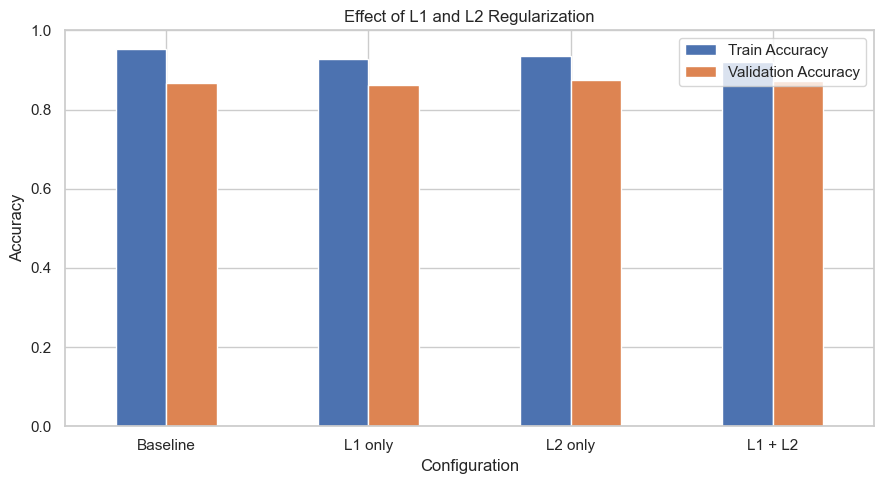

In [37]:
regularization_df.set_index("Configuration")[
    ["Train Accuracy", "Validation Accuracy"]
].plot(kind="bar", figsize=(9, 5))

plt.title("Effect of L1 and L2 Regularization")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [38]:
depths = [1, 3, 5, 10, None]

depth_results = []

for depth in depths:
    model = DecisionTreeClassifier(
        max_depth=depth,
        random_state=42
    )

    model.fit(X_train, y_train)

    train_acc = accuracy_score(
        y_train, model.predict(X_train)
    )

    val_acc = accuracy_score(
        y_val, model.predict(X_val)
    )

    depth_results.append({
        "Max Depth": str(depth),
        "Train Accuracy": train_acc,
        "Validation Accuracy": val_acc,
        "Train-Val Gap": train_acc - val_acc
    })

depth_df = pd.DataFrame(depth_results)
display(depth_df.round(4))

,Max Depth,Train Accuracy,Validation Accuracy,Train-Val Gap
0,1,0.8641,0.8633,0.0008
1,3,0.8876,0.8438,0.0438
2,5,0.9238,0.8477,0.0761
3,10,0.9873,0.8398,0.1474
4,None,1.0000,0.8281,0.1719


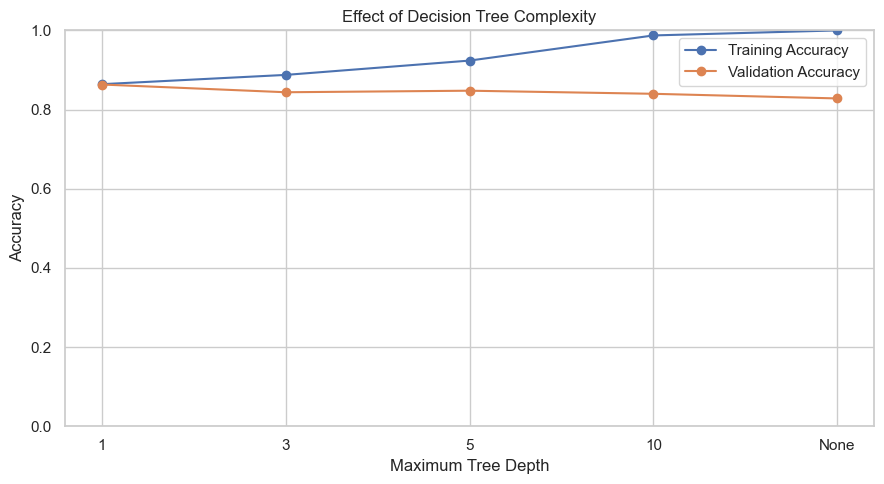

In [39]:
plt.figure(figsize=(9, 5))

plt.plot(
    depth_df["Max Depth"],
    depth_df["Train Accuracy"],
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    depth_df["Max Depth"],
    depth_df["Validation Accuracy"],
    marker="o",
    label="Validation Accuracy"
)

plt.title("Effect of Decision Tree Complexity")
plt.xlabel("Maximum Tree Depth")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.legend()
plt.tight_layout()
plt.show()